# 🩺 ENT Agent (Dr. Anees) — RAG Evaluation Notebook
**MedNexus AI Platform · Table 14 Supplementary Evaluation**
Generator **MedGemma (7B)** → Judge **Qwen 2.5-14B** · fully local via **Ollama** · 60 queries (30 diagnosis + 30 medication)

---
## 📌 What this notebook does
It evaluates a Retrieval-Augmented-Generation (RAG) agent for ENT medicine in two layers:

| Layer | Question answered | How it is measured | Needs an LLM? |
|---|---|---|---|
| **Retrieval** | Did the system find the right text? | Cosine similarity (BGE-large) between ground truth and each retrieved chunk → Recall, Precision, MRR, NDCG, P@k, R@k | No |
| **Generation** | Is the final answer good? | Qwen 2.5-14B as judge, 5 RAGAS-style metrics → Faithfulness, Correctness, Context Precision, Answer Relevance, Context Recall | Yes |

## 🔄 Pipeline (per query)
```
question ─► Pinecone (MedEmbed, top-25) ─► BGE reranker ─► top-7 chunks ─► context (≤10,000 chars)
                                                                              │
                      ground truth ──┬───────────────────────────────────────┤
                                     ▼                                         ▼
                 Retrieval metrics (embedding-based)          MedGemma answer (+ guardrail retries)
                                                                              │
                                                                              ▼
                                                           Qwen 2.5-14B judge → 5 generation metrics
```

## ▶️ How to run (Kaggle)
1. **Accelerator:** GPU (T4 ×2 recommended) · **Internet:** ON (Ollama + HuggingFace + Pinecone downloads).
2. **Add-ons → Secrets:** add `PINECONE_API_KEY_ENT` (or `PINECONE_API_KEY`) — a key for the Pinecone index `ent-specialist` (namespaces `diagnosis_knowledge`, `medication_knowledge`).
3. **Add Data:** attach the dataset `ent-evaluation-dataset2` (file `ent_evaluation_dataset.csv`, 200 rows; the first 30 per namespace are used).
4. Run **Part A** (install) → **Restart kernel** → run **Part B** (evaluation).
5. Expected runtime ≈ **36 min** for 60 queries (~36 s/query).

## 📂 Files produced (written to the working directory)
| File | Contents |
|---|---|
| `ent_results_<run>_*.csv` | one row per query: retrieval metrics + 5 judge scores |
| `ent_judgments_<run>_*.csv` | one row per query: full generated answer + 5 judge scores |
| `ent_metrics_<run>_*.json` | aggregated summary (overall / diagnosis / medication) |
| `ent_evaluation_plots_<run>.png` | 9-panel figure |

## 🗺️ Where to find each item of the paper
| Paper item | Notebook location |
|---|---|
| Experimental setup (Table in §3) | Part B · **Step 2 – Configuration** |
| Prompts (generation + 5 judges) | Part B · **Step 5 – Prompts** |
| Guardrails (loop / truncation / vague / missing dose) | Part B · **Step 6 – `LLMEvaluator.generate_with_retry`** |
| Retrieval metric formulas (§5.1) | Part B · **Step 7 – `retrieval_metrics`** |
| Judge metrics (§5.2) | Part B · **Step 6 – `LLMEvaluator.evaluate_all`** |
| Table 1 / Table 2 (overall, by namespace) | Part B · **Step 11 – Aggregate** and **Step 13 – Final report** (output at the bottom) |
| Runtime (Table 5) | Output line `Loop completed in 36.1 min` |
| Figure | Part B · **Step 12 – Figure** |

## ⚠️ Notes for reviewers
* Retrieval metrics are **embedding-only**; MRR/Precision@k/Recall@k use a fixed relevance threshold (0.45) and are therefore saturated (=1.0) on this query set. The *continuous* Recall/Precision are the discriminative retrieval measures.
* "Success rate" = fraction of queries with at least one retrieved chunk and no exception (a **system-reliability** measure, not correctness).
* All parameters are fixed (`temperature = 0`) for the generator and judge, so the run is deterministic up to GPU/numerical nondeterminism; the guardrail re-tries use `temperature = 0.3` only when a repetition loop is detected.
* The saved outputs below are from the run tagged **`20261025_150202`** and match the numbers reported in the paper.

---
# 🅰️ PART A — Environment Setup *(run once, then restart the kernel)*
Installs Ollama, NumPy 2.x, Pinecone v5, LangChain-core, sentence-transformers, etc. Nothing in this part computes a metric.
> ⚠️ After the last cell of Part A finishes, use **Run → Restart & Clear Cell Outputs**, then continue with Part B.

### A.1 · Install system + Python dependencies

In [ ]:
"""
PART A.1 — INSTALL ONLY
Run once, then RESTART KERNEL, then run Part B.
"""
import subprocess, sys, time, importlib

print("=" * 70)
print("PART A.1: Install dependencies")
print("=" * 70)

# ── Clean Pinecone ──
print("  Cleaning Pinecone packages...")
for pkg in ["pinecone-client", "pinecone", "langchain", "langchain-community"]:
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", pkg],
                   check=False, capture_output=True)
for path in [
    "/usr/local/lib/python3.13/dist-packages/pinecone",
    "/usr/local/lib/python3.13/dist-packages/pinecone_client",
    "/usr/local/lib/python3.13/dist-packages/langchain",
]:
    subprocess.run(["rm", "-rf", path], check=False)
for mod in list(sys.modules.keys()):
    if "pinecone" in mod or mod == "langchain":
        del sys.modules[mod]
importlib.invalidate_caches()
print("  Cleanup done")

# ── System deps ──
subprocess.run(["apt-get", "install", "-y", "zstd"], check=False)

# ── Install Ollama binary ──
try:
    subprocess.run(["ollama", "--version"], check=True, capture_output=True, timeout=5)
    print("  Ollama binary present")
except Exception:
    print("  Installing Ollama binary...")
    subprocess.run("curl -fsSL https://ollama.com/install.sh | sh", shell=True, check=True)

# ── Install Python packages ──
print("  Installing Python packages...")

# Step A: numpy 2.x first (fix "dtype size changed")
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
    "--force-reinstall", "numpy>=2.0,<3.0", "pandas>=2.0"], check=True)

# Step B: ollama + pinecone
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
    "ollama>=0.4.0",
    "pinecone>=5.4.0,<6.0.0"], check=True)

# Step C: langchain CORE only (no `langchain` meta package)
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
    "langchain-core>=0.3.0,<0.4.0",
    "langchain-huggingface>=0.1.0",
    "langchain-pinecone>=0.2.0",
    "sentence-transformers>=2.7.0",
    "python-dotenv>=1.0.0",
    "tqdm>=4.66.0",
    "matplotlib>=3.7.0",
    "seaborn>=0.13.0"], check=True)

# ── Verify ──
print("  Verifying...")
import numpy
print(f"    numpy {numpy.__version__}")
assert numpy.__version__.startswith("2."), "numpy must be >=2.0"
from pinecone import Pinecone
import pinecone as pc_pkg
print(f"    pinecone {getattr(pc_pkg, '__version__', '?')}")
import ollama
print(f"    ollama OK")
import langchain_core
print(f"    langchain-core {langchain_core.__version__}")

print("\n" + "=" * 70)
print("PART A COMPLETE")
print("=" * 70)
print("\n  ⚠️ RESTART KERNEL NOW, then run Part B.")
print("  Kaggle: Run → Restart & Clear Cell Outputs")
print("  Colab:  Runtime → Restart runtime")
print("=" * 70)

### A.2 · Remove deprecated Pinecone inference plugin
*(avoids import conflicts with `pinecone>=5.4`)*

In [ ]:
# ── Remove deprecated pinecone-plugin-inference ──
print("  Removing deprecated pinecone-plugin-inference...")
subprocess.run(
    [sys.executable, "-m", "pip", "uninstall", "-y",
     "pinecone-plugin-inference", "pinecone-client"],
    check=False, capture_output=True,
)

# Also remove any leftover plugin directory
for path in [
    "/usr/local/lib/python3.13/dist-packages/pinecone_plugin_inference",
    "/usr/local/lib/python3.13/dist-packages/pinecone-plugin-inference",
]:
    subprocess.run(["rm", "-rf", path], check=False)

# Clear cached modules
for mod in list(sys.modules.keys()):
    if "pinecone" in mod:
        del sys.modules[mod]
importlib.invalidate_caches()
print("  Plugin cleanup done")

### A.3 · Sanity check of imports
Expected last line: `✅ All imports OK — proceed to Cell 2`.

In [ ]:
# ── Verify (quick check, ~5 sec) ──
print("  Verifying...")
import numpy
print(f"    numpy {numpy.__version__}")
assert numpy.__version__.startswith("2."), "numpy must be >=2.0"

from pinecone import Pinecone
import pinecone as pc_pkg
print(f"    pinecone {getattr(pc_pkg, '__version__', '?')}")

import ollama
print(f"    ollama OK")

import langchain_core
print(f"    langchain-core {langchain_core.__version__}")

print("\n  ✅ All imports OK — proceed to Part B")

---
# 🅱️ PART B — Full Evaluation (single cell)
The cell below is organised in **13 numbered sections**. Search for the banner `# ====` to jump between them.

| # | Section | What happens |
|---|---|---|
| 0 | Imports + display helpers | pretty-printing utilities (no logic) |
| 1 | Ollama + models | start server, pull `medgemma` and `qwen2.5:14b` |
| 2 | Configuration | **all tunable parameters** (thresholds, k, token limits, dataset path) |
| 3 | Credentials | load Pinecone key from `.env` or Kaggle Secrets |
| 4 | Embeddings + reranker | MedEmbed (retrieval), BGE-large (metric similarity), BGE-reranker-v2-m3 |
| 5 | Prompts | generation prompt + 5 judge prompts |
| 6 | Classes | `OllamaChat`, `LLMEvaluator` (generation, guardrails, judging) |
| 7 | Retrieval + metrics | `retrieve`, `combine_context`, `retrieval_metrics` |
| 8 | Pin models in GPU | keeps both models loaded for 30 min |
| 9 | Dataset | selects 30 diagnosis + 30 medication questions |
| 10 | Evaluation loop | per query: retrieve → generate → score |
| 11 | Aggregate + save | CSV/JSON files |
| 12 | Figure | 9-panel PNG |
| 13 | Final report | summary printed at the bottom of the output |


  STEP 1/7 · OLLAMA SERVER + MODELS
  Status                         Starting server...
    Status                       Server up
  Ensuring medgemma           ... OK
  Ensuring qwen2.5:14b        ... OK

  STEP 2/7 · CONFIGURATION
    Generator model              medgemma
    Evaluator model              qwen2.5:14b
    Index                        ent-specialist
    K (retrieve → rerank → final) 25 → 7
    Similarity threshold         0.45
    Generation max tokens        600
    Evaluation max tokens        1000
    Diagnosis queries            30
    Medication queries           30
    Stream answers               True

  STEP 3/7 · API CREDENTIALS
    Status                       Loaded OK

  STEP 4/7 · EMBEDDING MODELS + RERANKER
  Loading MedEmbed (embedding model)...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

 OK
  Loading BGE similarity model...

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

 OK
  Loading BGE reranker...

...

Overall:  98%|██████████████████████████████▍| 59/60 [35:32<00:35, 35.76s/query, [60/60] medication]

 0.400  (6.3s)

──────────────────────────────────────────────────────────────────────────────
  Query score summary
──────────────────────────────────────────────────────────────────────────────
    Faithfulness      [████████████████████] 1.000
    Answer Correctness[████████████░░░░░░░░] 0.600
    Context Precision [████████████░░░░░░░░] 0.600
    Answer Relevance  [███████████████████░] 0.950
    Context Recall    [████████░░░░░░░░░░░░] 0.400

╔════════════════════════════════════════════════════════════════════════════╗
║ QUERY 60/60  ·  MEDICATION_KNOWLEDGE          ║
╚════════════════════════════════════════════════════════════════════════════╝
  Q: What is the management of post-operative secondary haemorrhage after tonsillectomy?

  ── RETRIEVAL ──
  7 docs retrieved in 1.7s
  Reranker: ON

  Rank     Rerank  Preview
  ------ --------  ----------------------------------------------------------
  1        0.9538  Post-tonsillectomy haemorrhage / Management  113  l Resus...
  2 

Overall: 100%|███████████████████████████████| 60/60 [36:05<00:00, 36.08s/query, [60/60] medication]

 0.500  (7.4s)

──────────────────────────────────────────────────────────────────────────────
  Query score summary
──────────────────────────────────────────────────────────────────────────────
    Faithfulness      [█████████████████░░░] 0.830
    Answer Correctness[████████████░░░░░░░░] 0.600
    Context Precision [███████████████░░░░░] 0.750
    Answer Relevance  [███████████████████░] 0.950
    Context Recall    [██████████░░░░░░░░░░] 0.500

  Loop completed in 36.1 min (36.1s per query)

  AGGREGATING RESULTS

  GENERATING FIGURE (9 panels)



/tmp/ipykernel_840/4025518060.py:736: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([d_s, m_s], labels=["Diagnosis","Medication"], patch_artist=True)


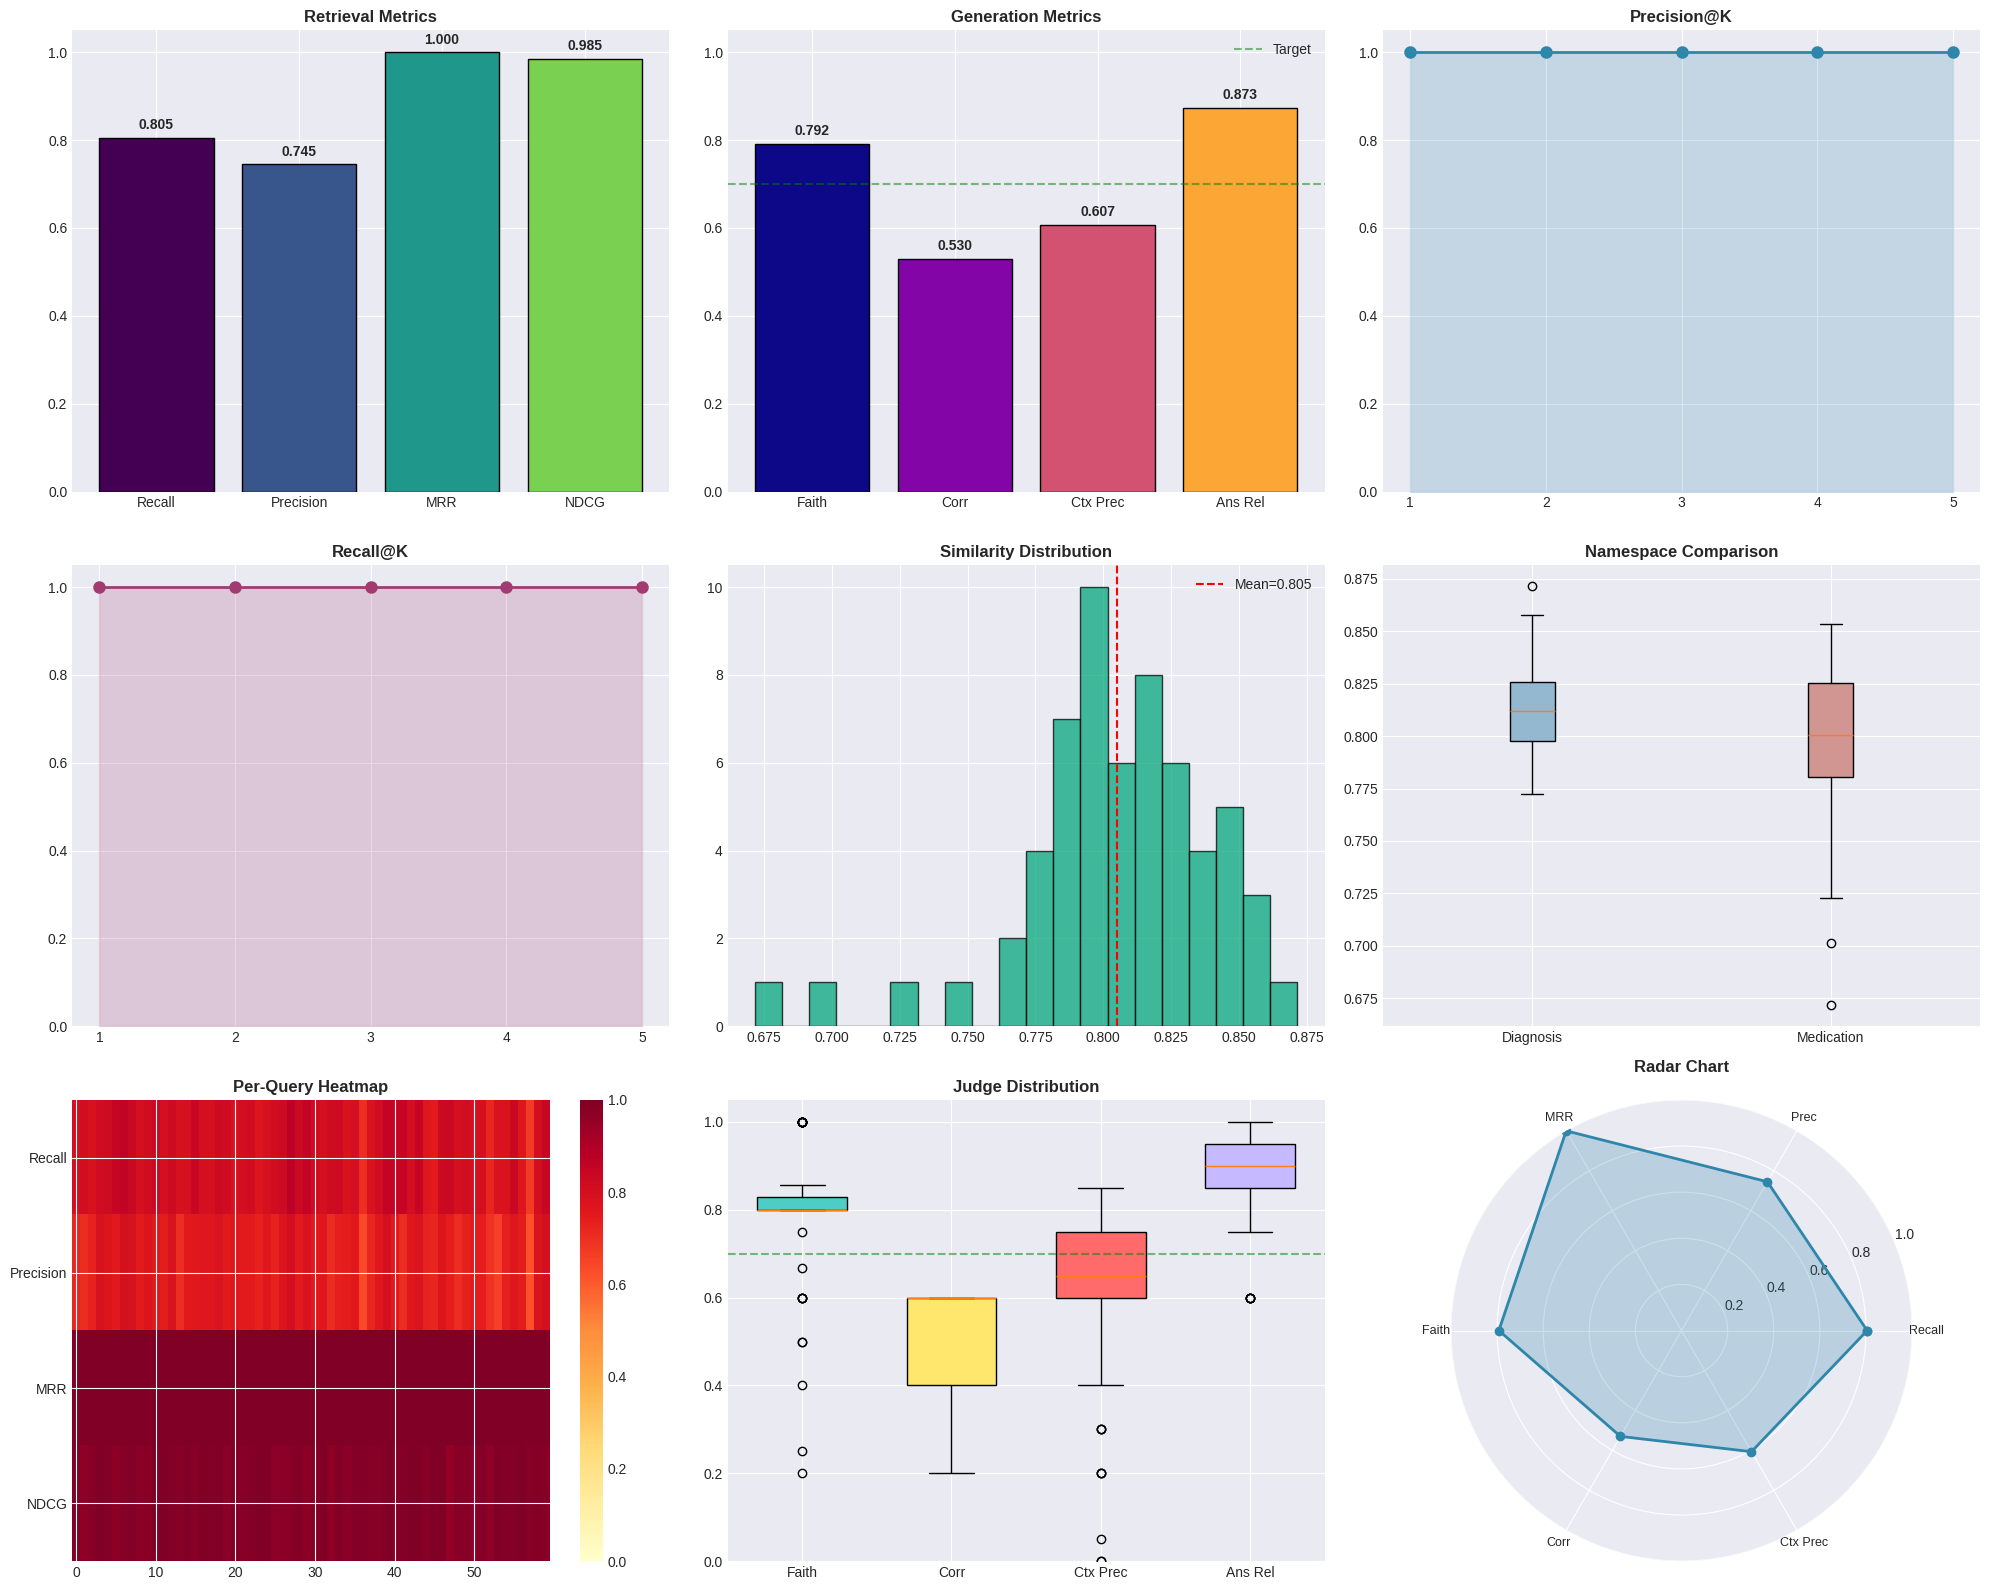

  ✓ Figure saved

  FINAL REPORT
    ┌─────────────────────────────────────┐
    │ Run:              20261025_150202   │
    │ Generator:        medgemma          │
    │ Evaluator:        qwen2.5:14b       │
    │ Queries:          60 (30D + 30M)    │
    │ Success rate:     100.0%            │
    │ Reranker:         ON                │
    │ Total runtime:    36.1 min          │
    └─────────────────────────────────────┘

  ── RETRIEVAL ──
    context_recall         [████████████████░░░░] 0.805
    context_precision      [███████████████░░░░░] 0.745
    mrr                    [████████████████████] 1.000
    ndcg                   [████████████████████] 0.985

  ── GENERATION (LLM judge) ──
    faithfulness           [████████████████░░░░] 0.792
    correctness            [███████████░░░░░░░░░] 0.530
    context_precision      [████████████░░░░░░░░] 0.607
    answer_relevance       [█████████████████░░░] 0.873
    context_recall         [████████░░░░░░░░░░░░] 0.381

  ── DIAGNOSIS 

In [4]:
"""
PART B — FULL EVALUATION PIPELINE (ENT / Dr. Anees RAG agent)
Generator : MedGemma (7B)      | Judge : Qwen 2.5-14B  (both local, Ollama)
Retrieval : MedEmbed -> Pinecone -> BGE reranker
Run AFTER Part A and a kernel restart. See the section map in the markdown cell above.
"""
import os, sys, json, re, time, subprocess
from collections import Counter
from datetime import datetime
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from dotenv import load_dotenv
import ollama
from langchain_core.prompts import PromptTemplate
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_pinecone import PineconeVectorStore
from sentence_transformers import SentenceTransformer, CrossEncoder

try:
    from kaggle_secrets import UserSecretsClient
except ImportError:
    UserSecretsClient = None

# ============================================================
# 0. HELPERS — progress display only
#    Pretty-print utilities (headers, key/value rows, ASCII score bars).
#    They do NOT affect any metric.
# ============================================================
def h1(title):
    print("\n" + "=" * 78)
    print(f"  {title}")
    print("=" * 78)

def h2(title):
    print("\n" + "─" * 78)
    print(f"  {title}")
    print("─" * 78)

def kv(key, value, indent=4, width=28):
    print(f"{' ' * indent}{key:<{width}} {value}")

def truncate(text, n=120):
    text = text.replace("\n", " ").strip()
    return text if len(text) <= n else text[:n-3] + "..."

def box(lines, indent=4):
    """Draw a simple ASCII box around lines."""
    if not lines:
        return
    w = max(len(l) for l in lines) + 4
    print(" " * indent + "┌" + "─" * w + "┐")
    for l in lines:
        print(" " * indent + "│ " + l.ljust(w - 2) + " │")
    print(" " * indent + "└" + "─" * w + "┘")

def score_bar(score, width=20):
    """ASCII bar for 0-1 scores."""
    filled = int(round(score * width))
    bar = "█" * filled + "░" * (width - filled)
    return f"[{bar}] {score:.3f}"

# ============================================================
# 1. START OLLAMA SERVER + PULL MODELS
#    GENERATOR_MODEL produces the answers; EVALUATOR_MODEL (a different model family)
#    acts as the LLM judge -> avoids self-evaluation bias.
# ============================================================
h1("STEP 1/7 · OLLAMA SERVER + MODELS")

GENERATOR_MODEL = "medgemma"
EVALUATOR_MODEL = "qwen2.5:14b"

try:
    subprocess.run(["ollama", "list"], check=True, capture_output=True, timeout=5)
    kv("Status", "Server already running")
except Exception:
    print("  Status                         Starting server...")
    with open("ollama_server.log", "w") as f:
        subprocess.Popen(["ollama", "serve"], stdout=f, stderr=f)
    time.sleep(10)
    try:
        subprocess.run(["ollama", "list"], check=True, capture_output=True, timeout=10)
        kv("Status", "Server up")
    except Exception as e:
        raise RuntimeError(f"Ollama server failed to start: {e}") from e

for m in [GENERATOR_MODEL, EVALUATOR_MODEL]:
    print(f"  Ensuring {m:<18} ...", end="", flush=True)
    subprocess.run(["ollama", "pull", m], check=True, capture_output=True)
    print(" OK")

# ============================================================
# 2. CONFIGURATION  (all tunable parameters live here)
#    SIMILARITY_THRESHOLD : a chunk counts as 'relevant' if cos-sim(ground truth, chunk) >= 0.45
#    K_RETRIEVE_FOR_RERANK : candidates fetched from Pinecone before reranking (25)
#    K_RETRIEVAL          : chunks kept after reranking and given to the generator (7)
#    MAX_CHUNK_LENGTH     : texts are truncated to this many chars before embedding (metric side)
#    GENERATOR/EVALUATOR_MAX_TOKENS : output limits for answer (600) and judge JSON (1000)
#    NUM_CTX              : Ollama context window (16,384 tokens)
# ============================================================
h1("STEP 2/7 · CONFIGURATION")

SIMILARITY_THRESHOLD   = 0.45
MAX_CHUNK_LENGTH       = 4000
K_RETRIEVAL            = 7
K_RETRIEVE_FOR_RERANK  = 25
GENERATOR_MAX_TOKENS   = 600
EVALUATOR_MAX_TOKENS   = 1000
NUM_CTX                = 16384
STREAM_ANSWERS         = True   # set True if you want to watch token output
PINECONE_INDEX_NAME    = "ent-specialist"
N_DIAGNOSIS_QUESTIONS  = 30
N_MEDICATION_QUESTIONS = 30
DATASET_PATH = "/kaggle/input/datasets/salmankey/ent-evaluation-dataset2/ent_evaluation_dataset.csv"

kv("Generator model", GENERATOR_MODEL)
kv("Evaluator model", EVALUATOR_MODEL)
kv("Index", PINECONE_INDEX_NAME)
kv("K (retrieve → rerank → final)", f"{K_RETRIEVE_FOR_RERANK} → {K_RETRIEVAL}")
kv("Similarity threshold", SIMILARITY_THRESHOLD)
kv("Generation max tokens", GENERATOR_MAX_TOKENS)
kv("Evaluation max tokens", EVALUATOR_MAX_TOKENS)
kv("Diagnosis queries", N_DIAGNOSIS_QUESTIONS)
kv("Medication queries", N_MEDICATION_QUESTIONS)
kv("Stream answers", STREAM_ANSWERS)

# ============================================================
# 3. API CREDENTIALS
#    Only the Pinecone key is needed (vector DB). No LLM API key is used:
#    both LLMs run locally through Ollama.
# ============================================================
h1("STEP 3/7 · API CREDENTIALS")

load_dotenv()
PINECONE_KEY = os.getenv("PINECONE_API_KEY")
if not PINECONE_KEY and UserSecretsClient:
    try:
        s = UserSecretsClient()
        try:
            PINECONE_KEY = s.get_secret("PINECONE_API_KEY_ENT")
            kv("Source", "PINECONE_API_KEY_ENT")
        except Exception:
            PINECONE_KEY = s.get_secret("PINECONE_API_KEY")
            kv("Source", "PINECONE_API_KEY")
    except Exception as e:
        print(f"  Kaggle secrets failed: {e}")

if not PINECONE_KEY:
    raise RuntimeError("PINECONE_API_KEY not found")
os.environ["PINECONE_API_KEY"] = PINECONE_KEY
os.environ["LANGCHAIN_TRACING_V2"] = "false"
kv("Status", "Loaded OK")

# ============================================================
# 4. EMBEDDING MODELS + RERANKER
#    embedding_model  : MedEmbed-base-v0.1 (768-d) - used to query Pinecone
#    similarity_model : bge-large-en-v1.5 - used ONLY to compute retrieval metrics
#    reranker         : bge-reranker-v2-m3 cross-encoder - re-orders the top-25 -> top-7
#    Embeddings are L2-normalised, so dot product == cosine similarity.
# ============================================================
h1("STEP 4/7 · EMBEDDING MODELS + RERANKER")

print("  Loading MedEmbed (embedding model)...", end="", flush=True)
embedding_model = HuggingFaceEmbeddings(
    model_name="abhinand/MedEmbed-base-v0.1",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True},
)
print(" OK")

print("  Loading BGE similarity model...", end="", flush=True)
similarity_model = SentenceTransformer("BAAI/bge-large-en-v1.5", device="cpu")
print(" OK")

print("  Loading BGE reranker...", end="", flush=True)
try:
    reranker = CrossEncoder("BAAI/bge-reranker-v2-m3")
    USE_RERANKER = True
    print(" OK")
except Exception as e:
    print(f" FAILED ({e})")
    reranker = None
    USE_RERANKER = False

kv("Reranker enabled", USE_RERANKER)

# ============================================================
# 5. PROMPTS
#    1 generation prompt (context-only, verbatim numbers, <=6 bullets)
#    5 judge prompts (RAGAS-style) -> each returns JSON {score, reasoning}
# ============================================================
h1("STEP 5/7 · PROMPTS")

ANSWER_GENERATION_PROMPT = PromptTemplate(
    input_variables=["question", "context"],
    template="""You are an ENT specialist writing a comprehensive clinical answer.

RULES:
1. Use ONLY information from the CONTEXT below.
2. QUOTE SPECIFIC NUMBERS VERBATIM when present.
3. Include drug name, dose, route, frequency, duration, rationale,
   contraindications, alternatives — when present.
4. DO NOT REPEAT YOURSELF. Max 6 bullet points. Finish every sentence.
5. Aim for 150-300 words.

QUESTION: {question}
CONTEXT:
{context}
ANSWER:"""
)

FAITHFULNESS_PROMPT = PromptTemplate(
    input_variables=["question", "answer", "context"],
    template="""Evaluate if the ANSWER is FAITHFULLY grounded in the CONTEXT.
Score = supported claims / total claims. Be strict.
Output ONLY JSON: {{"faithfulness_score": 0.0-1.0, "reasoning": "brief"}}

QUESTION: {question}
CONTEXT: {context}
ANSWER: {answer}"""
)

ANSWER_CORRECTNESS_PROMPT = PromptTemplate(
    input_variables=["question", "answer", "ground_truth"],
    template="""Compare the ANSWER to the GROUND TRUTH.
- 1.0 = all key facts | 0.8 = most | 0.6 = core | 0.4 = misses core | 0.2 = barely | 0.0 = wrong
Output ONLY JSON: {{"correctness_score": 0.0-1.0, "reasoning": "brief"}}

QUESTION: {question}
GROUND TRUTH: {ground_truth}
ANSWER: {answer}"""
)

CONTEXT_PRECISION_PROMPT = PromptTemplate(
    input_variables=["question", "context"],
    template="""Score proportion of CONTEXT relevant to QUESTION.
Output ONLY JSON: {{"context_precision_score": 0.0-1.0, "reasoning": "brief"}}

QUESTION: {question}
CONTEXT: {context}"""
)

ANSWER_RELEVANCE_PROMPT = PromptTemplate(
    input_variables=["question", "answer"],
    template="""Score how RELEVANT the ANSWER is to the QUESTION.
Output ONLY JSON: {{"answer_relevance_score": 0.0-1.0, "reasoning": "brief"}}

QUESTION: {question}
ANSWER: {answer}"""
)

CONTEXT_RECALL_PROMPT = PromptTemplate(
    input_variables=["ground_truth", "context"],
    template="""Score proportion of GROUND TRUTH covered in CONTEXT.
Output ONLY JSON: {{"context_recall_score": 0.0-1.0, "reasoning": "brief"}}

GROUND TRUTH: {ground_truth}
CONTEXT: {context}"""
)

kv("Generation prompt", "comprehensive clinical, verbatim quoting, no repetition")
kv("Judge prompts", "5 × RAGAS-style JSON")

# ============================================================
# 6. CLASSES
#    OllamaChat   : thin wrapper over ollama.chat (JSON mode for judging, streaming for answers)
#    LLMEvaluator : answer generation with GUARDRAILS + the 5 LLM-judge metrics
# ============================================================
class OllamaChat:
    """Minimal Ollama client. invoke() = JSON-mode call (judge); stream_invoke() = streamed text (generator)."""
    def __init__(self, model, temperature=0, max_tokens=1000, num_ctx=16384):
        self.model = model
        self.options = {
            "temperature": temperature,
            "num_predict": max_tokens,
            "num_ctx": num_ctx,
            "stop": ["\n\nUser:", "\n\nQuestion:", "\n\nHuman:", "</s>", "<|eot_id|>"],
        }

    def invoke(self, prompt):
        resp = ollama.chat(
            model=self.model,
            messages=[{"role": "user", "content": prompt}],
            options=self.options, format="json",
        )
        return resp["message"]["content"]

    def stream_invoke(self, prompt, echo=True, temperature_override=None):
        opts = dict(self.options)
        if temperature_override is not None:
            opts["temperature"] = temperature_override
        stream = ollama.chat(
            model=self.model,
            messages=[{"role": "user", "content": prompt}],
            options=opts, stream=True,
        )
        text = ""
        for chunk in stream:
            piece = chunk["message"]["content"]
            text += piece
            if echo:
                print(piece, end="", flush=True)
        if echo:
            print()
        return text


class LLMEvaluator:
    """Generates answers (with guardrails) and scores them with the judge model."""
    def __init__(self, gen_model, eval_model):
        self.generator_llm = OllamaChat(gen_model, max_tokens=GENERATOR_MAX_TOKENS, num_ctx=NUM_CTX)
        self.evaluator_llm = OllamaChat(eval_model, max_tokens=EVALUATOR_MAX_TOKENS, num_ctx=NUM_CTX)
        kv("Generator", gen_model)
        kv("Evaluator", eval_model)

    @staticmethod
    def _parse_json(text):
        # Extract the first {...} block from the judge reply; returns {} if unparsable (score then defaults to 0).
        m = re.search(r"\{.*\}", text, re.DOTALL)
        if not m:
            return {}
        try:
            return json.loads(m.group())
        except json.JSONDecodeError:
            return {}

    @staticmethod
    def _is_loop(text):
        # GUARDRAIL 1 - repetition loop: >=3 identical lines, last-200-chars repeated >=3x, or type/token ratio < 0.15
        if len(text) < 300:
            return False
        lines = [l.strip() for l in text.split("\n") if l.strip()]
        if len(lines) >= 3 and Counter(lines).most_common(1)[0][1] >= 3:
            return True
        if len(text) >= 400 and text.count(text[-200:]) >= 3:
            return True
        words = text.lower().split()
        if len(words) > 100 and len(set(words)) / len(words) < 0.15:
            return True
        return False

    @staticmethod
    def _truncate(text):
        # Fallback clean-up: cut at the first repeated line and make sure the text ends with punctuation.
        lines = text.split("\n")
        seen, out = set(), []
        for line in lines:
            s = line.strip()
            if not s:
                out.append(line); continue
            if s in seen:
                break
            seen.add(s); out.append(line)
        r = "\n".join(out).rstrip()
        return r if not r or r.endswith((".", "!", "?")) else r + "."

    def generate_with_retry(self, question, context, retries=2):
        # Generate once, then check 4 failure modes and regenerate (max `retries`) if any is detected:
        #   loop | truncated (no terminal punctuation) | vague dose wording | missing numeric dose on drug/treatment questions
        prompt = ANSWER_GENERATION_PROMPT.format(question=question, context=context[:12000])
        print(f"    → Generating answer with {self.generator_llm.model}...")
        t0 = time.time()
        answer = self.generator_llm.stream_invoke(prompt, echo=STREAM_ANSWERS).strip()
        dt = time.time() - t0
        print(f"      ✓ {len(answer)} chars in {dt:.1f}s")

        for attempt in range(retries):
            is_loop = self._is_loop(answer)
            is_trunc = answer and not answer.rstrip().endswith((".", "!", "?", ")", "]"))
            is_vague = bool(re.search(r"(appropriate dose|individualized|dose per (weight|age))", answer, re.I))
            has_dose = bool(re.search(r"\d+\s*(mg|mcg|g|ml|units?|mg/kg|iu|meq)", answer, re.I))
            needs_dose = bool(re.search(r"(treatment|regimen|drug|antibiotic|therapy|dose|duration)", question, re.I))
            is_missing = needs_dose and not has_dose and not is_loop

            if not (is_loop or is_trunc or is_vague or is_missing):
                break

            reasons = [r for r, f in [("loop", is_loop), ("trunc", is_trunc),
                                       ("vague", is_vague), ("missing", is_missing)] if f]
            print(f"      ⚠ Retry {attempt+1}/{retries} ({', '.join(reasons)})")

            rq = question
            if is_loop:
                rq += "\n\nCRITICAL: Do not repeat. Write 3-5 bullet points only. State diagnosis and evidence plainly."
            if is_trunc:
                rq += "\n\nCRITICAL: Finish every sentence with a period."
            if is_vague or is_missing:
                rq += "\n\nCRITICAL: Quote specific doses verbatim from context."

            rp = ANSWER_GENERATION_PROMPT.format(question=rq, context=context[:12000])
            temp = 0.3 if is_loop else 0
            cand = self.generator_llm.stream_invoke(rp, echo=STREAM_ANSWERS, temperature_override=temp).strip()
            print(f"      → {len(cand)} chars")

            if not self._is_loop(cand) and len(cand) > 50:
                answer = cand
            else:
                answer = self._truncate(answer)
                break

        if self._is_loop(answer):
            answer = self._truncate(answer)
        return answer

    def judge(self, template, **kwargs):
        # Fill a judge prompt, call the evaluator model in JSON mode, parse the JSON.
        return self._parse_json(self.evaluator_llm.invoke(template.format(**kwargs)))

    def evaluate_all(self, q, ans, gt, ctx):
        # The 5 LLM-as-judge metrics (all scored in [0,1]); judge sees at most 3000 chars of context, 2000 of ground truth.
        h2("Running LLM-as-judge (5 metrics)")
        results = {}

        print("    [1/5] Faithfulness...", end="", flush=True)
        t0 = time.time()
        results["faithfulness"] = self.judge(FAITHFULNESS_PROMPT, question=q, answer=ans, context=ctx[:3000])
        print(f" {results['faithfulness'].get('faithfulness_score', 0):.3f}  ({time.time()-t0:.1f}s)")

        print("    [2/5] Answer correctness...", end="", flush=True)
        t0 = time.time()
        results["correctness"] = self.judge(ANSWER_CORRECTNESS_PROMPT, question=q, answer=ans, ground_truth=gt[:2000])
        print(f" {results['correctness'].get('correctness_score', 0):.3f}  ({time.time()-t0:.1f}s)")

        print("    [3/5] Context precision...", end="", flush=True)
        t0 = time.time()
        results["context_precision"] = self.judge(CONTEXT_PRECISION_PROMPT, question=q, context=ctx[:3000])
        print(f" {results['context_precision'].get('context_precision_score', 0):.3f}  ({time.time()-t0:.1f}s)")

        print("    [4/5] Answer relevance...", end="", flush=True)
        t0 = time.time()
        results["relevance"] = self.judge(ANSWER_RELEVANCE_PROMPT, question=q, answer=ans)
        print(f" {results['relevance'].get('answer_relevance_score', 0):.3f}  ({time.time()-t0:.1f}s)")

        print("    [5/5] Context recall...", end="", flush=True)
        t0 = time.time()
        results["context_recall"] = self.judge(CONTEXT_RECALL_PROMPT, ground_truth=gt[:2000], context=ctx[:3000])
        print(f" {results['context_recall'].get('context_recall_score', 0):.3f}  ({time.time()-t0:.1f}s)")

        return results

# ============================================================
# 7. RETRIEVAL + EMBEDDING-BASED METRICS
#    sem_sim(a,b)            : cosine similarity with BGE-large (cached)
#    retrieve()              : Pinecone top-25 -> cross-encoder rerank -> top-7
#    combine_context()       : builds the generator context (<=10,000 chars, <=2,000 per chunk)
#    retrieval_metrics()     : Recall(max sim), Precision(mean sim), MRR, NDCG, P@k, R@k
# ============================================================
@lru_cache(maxsize=1000)
def _encode(text):
    # Cached, L2-normalised BGE-large embedding (text truncated to MAX_CHUNK_LENGTH).
    if len(text) > MAX_CHUNK_LENGTH:
        text = text[:MAX_CHUNK_LENGTH]
    return similarity_model.encode([text], normalize_embeddings=True)

def sem_sim(a, b):
    return float(np.dot(_encode(a)[0], _encode(b)[0]))

def retrieve(query, namespace):
    store = PineconeVectorStore(
        index_name=PINECONE_INDEX_NAME, embedding=embedding_model, namespace=namespace)
    k = K_RETRIEVE_FOR_RERANK if USE_RERANKER else K_RETRIEVAL
    docs = store.as_retriever(search_kwargs={"k": k}).invoke(query)

    if not USE_RERANKER or reranker is None or len(docs) <= 1:
        return docs[:K_RETRIEVAL]

    scores = reranker.predict([[query, d.page_content] for d in docs])
    ranked = sorted(zip(docs, scores), key=lambda x: x[1], reverse=True)
    out = []
    for doc, score in ranked[:K_RETRIEVAL]:
        doc.metadata["rerank_score"] = float(score)
        out.append(doc)
    return out

def combine_context(docs, max_chars=10000, per_doc_chars=2000):
    parts, total = [], 0
    for i, d in enumerate(docs, 1):
        chunk = d.page_content[:per_doc_chars]
        part = f"[Doc {i}]\n{chunk}\n"
        if total + len(part) > max_chars:
            break
        parts.append(part)
        total += len(part)
    return "\n".join(parts)

def retrieval_metrics(gt, docs):
    # sims[i] = cos(ground_truth, doc_i). Relevant <=> sims[i] >= SIMILARITY_THRESHOLD.
    #   recall    = max(sims)            precision = mean(sims)
    #   mrr       = 1/rank of first relevant doc
    #   ndcg      = DCG/IDCG with graded gain = sim
    #   P@k / R@k = fraction relevant in top-k / any relevant in top-k
    if not docs:
        return dict(recall=0, precision=0, mrr=0, ndcg=0, p_at_k={}, r_at_k={}, sims=[])
    sims = [sem_sim(gt, d.page_content) for d in docs]
    mrr = 0.0
    for rank, s in enumerate(sims, 1):
        if s >= SIMILARITY_THRESHOLD:
            mrr = 1.0 / rank; break
    dcg = sum(s / np.log2(i + 2) for i, s in enumerate(sims))
    idcg = sum(s / np.log2(i + 2) for i, s in enumerate(sorted(sims, reverse=True)))
    ndcg = dcg / idcg if idcg > 0 else 0.0
    p_at_k = {k: sum(1 for s in sims[:k] if s >= SIMILARITY_THRESHOLD) / k for k in [1,2,3,4,5]}
    r_at_k = {k: float(any(s >= SIMILARITY_THRESHOLD for s in sims[:k])) for k in [1,2,3,4,5]}
    return dict(recall=float(max(sims)), precision=float(np.mean(sims)),
                mrr=float(mrr), ndcg=float(ndcg), p_at_k=p_at_k, r_at_k=r_at_k, sims=sims)

# ============================================================
# 8. PIN MODELS IN GPU MEMORY
#    keep_alive=30m prevents Ollama from unloading/reloading models between queries.
# ============================================================
h1("STEP 6/7 · PIN MODELS IN GPU")

for m in [GENERATOR_MODEL, EVALUATOR_MODEL]:
    try:
        ollama.generate(model=m, prompt=".", keep_alive="30m")
        print(f"  ✓ {m} pinned (30 min)")
    except Exception as e:
        print(f"  ⚠ Could not pin {m}: {e}")

# ============================================================
# 9. LOAD DATASET
#    Takes the first 30 'diagnosis_knowledge' + first 30 'medication_knowledge' rows.
#    Columns used: question, ground_truth, namespace.
# ============================================================
h1("STEP 7/7 · LOAD DATASET")

dataset = pd.read_csv(DATASET_PATH)
diag = dataset[dataset.namespace == "diagnosis_knowledge"].head(N_DIAGNOSIS_QUESTIONS)
med = dataset[dataset.namespace == "medication_knowledge"].head(N_MEDICATION_QUESTIONS)
selected = pd.concat([diag, med], ignore_index=True)

kv("Dataset path", DATASET_PATH.split("/")[-1])
kv("Total rows in file", len(dataset))
kv("Diagnosis queries", len(diag))
kv("Medication queries", len(med))
kv("Queries to evaluate", len(selected))

# ============================================================
# 10. EVALUATION LOOP  (one iteration = one query)
#    a) retrieve + rerank  b) build context  c) generate answer (with guardrails)
#    d) retrieval metrics  e) 5 LLM-judge metrics  f) store record
#    If a query raises an exception it is logged and stored with all scores = 0.
# ============================================================
h1("EVALUATION LOOP")
print(f"  Running {len(selected)} queries with {GENERATOR_MODEL} → {EVALUATOR_MODEL}")
print(f"  Progress bar shows overall completion.\n")

llm_evaluator = LLMEvaluator(GENERATOR_MODEL, EVALUATOR_MODEL)
results, judgments = [], []

run_start = time.time()
pbar = tqdm(range(len(selected)), desc="Overall", ncols=100, unit="query")

for idx in pbar:
    row = selected.iloc[idx]
    question, ground_truth, namespace = row.question, row.ground_truth, row.namespace

    print("\n" + "╔" + "═" * 76 + "╗")
    print(f"║ QUERY {idx+1}/{len(selected)}  ·  {namespace.upper():<30}║")
    print("╚" + "═" * 76 + "╝")
    pbar.set_postfix_str(f"[{idx+1}/{len(selected)}] {namespace.split('_')[0]}")

    print(f"  Q: {question}\n")

    try:
        # ---------- (a,b) Retrieval + rerank + context ----------
        print("  ── RETRIEVAL ──")
        t0 = time.time()
        docs = retrieve(question, namespace)
        dt = time.time() - t0
        if not docs:
            raise ValueError("No docs retrieved")

        print(f"  {len(docs)} docs retrieved in {dt:.1f}s")
        print(f"  Reranker: {'ON' if USE_RERANKER else 'OFF'}\n")

        # Show retrieved docs with scores
        print(f"  {'Rank':<6} {'Rerank':>8}  Preview")
        print(f"  {'-'*6} {'-'*8}  {'-'*58}")
        for i, d in enumerate(docs, 1):
            score = d.metadata.get("rerank_score", None)
            score_str = f"{score:.4f}" if score is not None else "  --  "
            preview = truncate(d.page_content, 60)
            print(f"  {i:<6} {score_str:>8}  {preview}")

        context = combine_context(docs)
        print(f"\n  Context built: {len(context)} chars\n")

        # ---------- (c) Generation with guardrails ----------
        print("  ── GENERATION ──")
        answer = llm_evaluator.generate_with_retry(question, context)
        print(f"\n  Answer preview:")
        for line in answer.split("\n")[:5]:
            print(f"    {truncate(line, 70)}")
        if answer.count("\n") > 5:
            print(f"    ... ({answer.count(chr(10)) - 5} more lines)")

        # ---------- (d) Embedding-based retrieval metrics ----------
        print("\n  ── RETRIEVAL METRICS ──")
        rm = retrieval_metrics(ground_truth, docs)
        print(f"    Recall (continuous)  {score_bar(rm['recall'])}")
        print(f"    Precision (cont.)    {score_bar(rm['precision'])}")
        print(f"    MRR                  {score_bar(rm['mrr'])}")
        print(f"    NDCG                 {score_bar(rm['ndcg'])}")
        print(f"    P@k                  " + "  ".join(
            f"@{k}={rm['p_at_k'][k]:.2f}" for k in [1,2,3,4,5]))
        print(f"    R@k                  " + "  ".join(
            f"@{k}={rm['r_at_k'][k]:.2f}" for k in [1,2,3,4,5]))

        # ---------- (e) LLM-as-judge metrics ----------
        jm = llm_evaluator.evaluate_all(question, answer, ground_truth, context)

        # ---------- (f) Store per-query records ----------
        j_record = {
            "query_id": idx + 1, "namespace": namespace, "question": question,
            "generated_answer": answer,
            "faithfulness": jm["faithfulness"].get("faithfulness_score", 0),
            "answer_correctness": jm["correctness"].get("correctness_score", 0),
            "context_precision_llm": jm["context_precision"].get("context_precision_score", 0),
            "answer_relevance": jm["relevance"].get("answer_relevance_score", 0),
            "context_recall_llm": jm["context_recall"].get("context_recall_score", 0),
        }
        judgments.append(j_record)

        results.append({
            "query_id": idx + 1, "namespace": namespace, "question": question,
            "ground_truth": ground_truth[:500], "generated_answer": answer[:500],
            "recall_continuous": rm["recall"],
            "precision_continuous": rm["precision"],
            "mrr": rm["mrr"], "ndcg_graded": rm["ndcg"],
            "best_similarity": rm["recall"],
            **{f"precision@{k}": v for k, v in rm["p_at_k"].items()},
            **{f"recall@{k}": v for k, v in rm["r_at_k"].items()},
            **{k: j_record[k] for k in [
                "faithfulness", "answer_correctness",
                "context_precision_llm", "answer_relevance", "context_recall_llm"]},
        })

        h2("Query score summary")
        print(f"    Faithfulness      {score_bar(j_record['faithfulness'])}")
        print(f"    Answer Correctness{score_bar(j_record['answer_correctness'])}")
        print(f"    Context Precision {score_bar(j_record['context_precision_llm'])}")
        print(f"    Answer Relevance  {score_bar(j_record['answer_relevance'])}")
        print(f"    Context Recall    {score_bar(j_record['context_recall_llm'])}")

    except Exception as e:
        print(f"\n  ✗ ERROR: {e}")
        import traceback; traceback.print_exc()
        results.append({
            "query_id": idx + 1, "namespace": namespace, "question": question,
            "ground_truth": ground_truth[:500], "generated_answer": f"ERROR: {e}",
            **{k: 0 for k in [
                "recall_continuous","precision_continuous","mrr","ndcg_graded",
                "best_similarity","faithfulness","answer_correctness",
                "context_precision_llm","answer_relevance","context_recall_llm",
                "precision@1","precision@2","precision@3","precision@4","precision@5",
                "recall@1","recall@2","recall@3","recall@4","recall@5"]},
        })

pbar.close()
elapsed = time.time() - run_start
print(f"\n{'='*78}")
print(f"  Loop completed in {elapsed/60:.1f} min ({elapsed/len(selected):.1f}s per query)")
print(f"{'='*78}")

# ============================================================
# 11. AGGREGATE + SAVE RESULTS
#    Overall metrics = mean over queries with best_similarity > 0 (retrieval) / all judged queries (generation).
#    success_rate = queries with >=1 retrieved chunk / total queries (system reliability, not correctness).
#    Saves: results CSV, judgments CSV, metrics JSON.
# ============================================================
h1("AGGREGATING RESULTS")

results_df = pd.DataFrame(results)
judgments_df = pd.DataFrame(judgments)

if judgments_df.empty:
    print("  ✗ WARNING: no judgments collected — all queries failed")
else:
    diag_df = results_df[results_df.namespace == "diagnosis_knowledge"]
    med_df = results_df[results_df.namespace == "medication_knowledge"]
    valid = results_df[results_df.best_similarity > 0]

    def subset(df):
        if df.empty:
            return {}
        return {
            "recall": float(df.recall_continuous.mean()),
            "precision": float(df.precision_continuous.mean()),
            "mrr": float(df.mrr.mean()),
            "faithfulness": float(df.faithfulness.mean()),
            "correctness": float(df.answer_correctness.mean()),
            "answer_relevance": float(df.answer_relevance.mean()),
        }

    run_tag = datetime.now().strftime("%Y%m%d_%H%M%S")
    summary = {
        "run_tag": run_tag,
        "timestamp": datetime.now().isoformat(),
        "generator_model": GENERATOR_MODEL,
        "evaluator_model": EVALUATOR_MODEL,
        "n_queries": len(results_df),
        "n_diagnosis": len(diag_df),
        "n_medication": len(med_df),
        "success_rate": float(len(valid) / len(results_df)) if len(results_df) else 0,
        "overall_retrieval": {
            "context_recall": float(valid.recall_continuous.mean()),
            "context_precision": float(valid.precision_continuous.mean()),
            "mrr": float(valid.mrr.mean()),
            "ndcg": float(valid.ndcg_graded.mean()),
            **{f"precision@{k}": float(valid[f"precision@{k}"].mean()) for k in [1,2,3,4,5]},
            **{f"recall@{k}": float(valid[f"recall@{k}"].mean()) for k in [1,2,3,4,5]},
        },
        "overall_generation": {
            "faithfulness": float(judgments_df.faithfulness.mean()),
            "correctness": float(judgments_df.answer_correctness.mean()),
            "context_precision": float(judgments_df.context_precision_llm.mean()),
            "answer_relevance": float(judgments_df.answer_relevance.mean()),
            "context_recall": float(judgments_df.context_recall_llm.mean()),
        },
        "diagnosis": subset(diag_df),
        "medication": subset(med_df),
    }

    ev_suffix = EVALUATOR_MODEL.replace(":", "-").replace("/", "-")
    rk_suffix = "_with_reranker" if USE_RERANKER else "_no_reranker"
    results_df.to_csv(f"ent_results_{run_tag}_{ev_suffix}{rk_suffix}.csv", index=False)
    judgments_df.to_csv(f"ent_judgments_{run_tag}_{ev_suffix}{rk_suffix}.csv", index=False)
    with open(f"ent_metrics_{run_tag}_{ev_suffix}{rk_suffix}.json", "w") as f:
        json.dump(summary, f, indent=2)

    # ============================================================
    # 12. FIGURE (9 panels)
    #    Retrieval bars | Generation bars | P@K | R@K | similarity histogram |
    #    namespace box-plot | per-query heatmap | judge-score box-plot | radar chart
    # ============================================================
    h1("GENERATING FIGURE (9 panels)")

    plt.style.use("seaborn-v0_8-darkgrid")
    fig = plt.figure(figsize=(20, 16))

    ax = fig.add_subplot(3, 3, 1)
    s = [summary["overall_retrieval"]["context_recall"],
         summary["overall_retrieval"]["context_precision"],
         summary["overall_retrieval"]["mrr"],
         summary["overall_retrieval"]["ndcg"]]
    b = ax.bar(["Recall", "Precision", "MRR", "NDCG"], s,
               color=plt.cm.viridis(np.linspace(0, .8, 4)), edgecolor="black")
    ax.set_ylim(0, 1.05); ax.set_title("Retrieval Metrics", fontweight="bold")
    for bi, v in zip(b, s): ax.text(bi.get_x()+bi.get_width()/2, bi.get_height()+.02,
                                    f"{v:.3f}", ha="center", fontweight="bold")

    ax = fig.add_subplot(3, 3, 2)
    s = [summary["overall_generation"]["faithfulness"],
         summary["overall_generation"]["correctness"],
         summary["overall_generation"]["context_precision"],
         summary["overall_generation"]["answer_relevance"]]
    b = ax.bar(["Faith", "Corr", "Ctx Prec", "Ans Rel"], s,
               color=plt.cm.plasma(np.linspace(0, .8, 4)), edgecolor="black")
    ax.set_ylim(0, 1.05); ax.axhline(.7, color="green", ls="--", alpha=.5, label="Target")
    ax.set_title("Generation Metrics", fontweight="bold"); ax.legend()
    for bi, v in zip(b, s): ax.text(bi.get_x()+bi.get_width()/2, bi.get_height()+.02,
                                    f"{v:.3f}", ha="center", fontweight="bold")

    for i, (title, key, color) in enumerate([
        ("Precision@K", "precision", "#2E86AB"),
        ("Recall@K", "recall", "#A23B72")], start=3):
        ax = fig.add_subplot(3, 3, i)
        ks = [1,2,3,4,5]
        vs = [summary["overall_retrieval"][f"{key}@{k}"] for k in ks]
        ax.plot(ks, vs, "o-", lw=2, ms=8, color=color)
        ax.fill_between(ks, vs, alpha=.2, color=color)
        ax.set_xticks(ks); ax.set_ylim(0,1.05); ax.set_title(title, fontweight="bold")

    ax = fig.add_subplot(3, 3, 5)
    sims = results_df.best_similarity.values
    ax.hist(sims, bins=20, color="#06A77D", edgecolor="black", alpha=.75)
    ax.axvline(sims.mean(), color="red", ls="--", label=f"Mean={sims.mean():.3f}")
    ax.set_title("Similarity Distribution", fontweight="bold"); ax.legend()

    ax = fig.add_subplot(3, 3, 6)
    d_s = results_df[results_df.namespace=="diagnosis_knowledge"].best_similarity
    m_s = results_df[results_df.namespace=="medication_knowledge"].best_similarity
    bp = ax.boxplot([d_s, m_s], labels=["Diagnosis","Medication"], patch_artist=True)
    bp["boxes"][0].set_facecolor("#95B8D1"); bp["boxes"][1].set_facecolor("#D19592")
    ax.set_title("Namespace Comparison", fontweight="bold")

    ax = fig.add_subplot(3, 3, 7)
    mat = results_df[["recall_continuous","precision_continuous","mrr","ndcg_graded"]].values.T
    im = ax.imshow(mat, aspect="auto", cmap="YlOrRd", vmin=0, vmax=1)
    ax.set_yticks(range(4)); ax.set_yticklabels(["Recall","Precision","MRR","NDCG"])
    ax.set_title("Per-Query Heatmap", fontweight="bold"); plt.colorbar(im, ax=ax)

    ax = fig.add_subplot(3, 3, 8)
    bp = ax.boxplot([judgments_df.faithfulness, judgments_df.answer_correctness,
                     judgments_df.context_precision_llm, judgments_df.answer_relevance],
                    positions=[1,2,3,4], widths=.6, patch_artist=True)
    for p, c in zip(bp["boxes"], ["#4ECDC4","#FFE66D","#FF6B6B","#C7B9FF"]): p.set_facecolor(c)
    ax.set_xticks([1,2,3,4]); ax.set_xticklabels(["Faith","Corr","Ctx Prec","Ans Rel"])
    ax.set_ylim(0,1.05); ax.axhline(.7, color="green", ls="--", alpha=.5)
    ax.set_title("Judge Distribution", fontweight="bold")

    ax = fig.add_subplot(3, 3, 9, projection="polar")
    cats = ["Recall","Prec","MRR","Faith","Corr","Ctx Prec"]
    vals = [summary["overall_retrieval"]["context_recall"],
            summary["overall_retrieval"]["context_precision"],
            summary["overall_retrieval"]["mrr"],
            summary["overall_generation"]["faithfulness"],
            summary["overall_generation"]["correctness"],
            summary["overall_generation"]["context_precision"]]
    ang = np.linspace(0, 2*np.pi, len(cats), endpoint=False).tolist()
    vals += vals[:1]; ang += ang[:1]
    ax.plot(ang, vals, "o-", lw=2, color="#2E86AB")
    ax.fill(ang, vals, alpha=.25, color="#2E86AB")
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(cats, fontsize=9); ax.set_ylim(0,1)
    ax.set_title("Radar Chart", fontweight="bold", pad=20)

    plt.tight_layout()
    plt.savefig(f"ent_evaluation_plots_{run_tag}.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print("  ✓ Figure saved")

    # ============================================================
    # 13. FINAL REPORT  (numbers reported in the paper - Tables 1 & 2)
    #    Printed summary box + retrieval, generation, diagnosis and medication scores.
    # ============================================================
    h1("FINAL REPORT")

    box([
        f"Run:              {run_tag}",
        f"Generator:        {GENERATOR_MODEL}",
        f"Evaluator:        {EVALUATOR_MODEL}",
        f"Queries:          {summary['n_queries']} ({summary['n_diagnosis']}D + {summary['n_medication']}M)",
        f"Success rate:     {summary['success_rate']*100:.1f}%",
        f"Reranker:         {'ON' if USE_RERANKER else 'OFF'}",
        f"Total runtime:    {elapsed/60:.1f} min",
    ])

    print(f"\n  ── RETRIEVAL ──")
    for k in ["context_recall", "context_precision", "mrr", "ndcg"]:
        print(f"    {k:<22} {score_bar(summary['overall_retrieval'][k])}")

    print(f"\n  ── GENERATION (LLM judge) ──")
    for k in ["faithfulness", "correctness", "context_precision", "answer_relevance", "context_recall"]:
        print(f"    {k:<22} {score_bar(summary['overall_generation'][k])}")

    print(f"\n  ── DIAGNOSIS ({summary['n_diagnosis']} queries) ──")
    if summary['diagnosis']:
        for k, v in summary['diagnosis'].items():
            print(f"    {k:<22} {score_bar(v)}")

    print(f"\n  ── MEDICATION ({summary['n_medication']} queries) ──")
    if summary['medication']:
        for k, v in summary['medication'].items():
            print(f"    {k:<22} {score_bar(v)}")

    print(f"\n  ── OUTPUT FILES ──")
    kv("Results CSV", f"ent_results_{run_tag}_*.csv")
    kv("Judgments CSV", f"ent_judgments_{run_tag}_*.csv")
    kv("Metrics JSON", f"ent_metrics_{run_tag}_*.json")
    kv("Figure PNG", f"ent_evaluation_plots_{run_tag}.png")

    print(f"\n{'='*78}")
    print(f"  ✅ EVALUATION COMPLETE · {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"{'='*78}")